In [1]:
pip install langchain_google_genai

In [2]:
from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.tools import tool
from langchain_google_genai import ChatGoogleGenerativeAI
from google.colab import userdata
from langchain_core.messages import HumanMessage, SystemMessage
from typing import Literal
from langgraph.prebuilt import ToolNode, tools_condition

In [3]:
orders_db = {
    "ORD-101": {
        "order_id": "ORD-101",
        "item_name": "Wireless Headphones",
        "price": 1500,
        "status": "Delivered",
        "days_since_delivery": 5
    },
    "ORD-102": {
        "order_id": "ORD-102",
        "item_name": "Mechanical Keyboard",
        "price": 2000,
        "status": "Shipped",
        "days_since_delivery": None
    },
    "ORD-103": {
        "order_id": "ORD-103",
        "item_name": "Smart Watch",
        "price": 3500,
        "status": "Delivered",
        "days_since_delivery": 20
    },
    "ORD-104": {
        "order_id": "ORD-104",
        "item_name": "Gaming Mouse",
        "price": 800,
        "status": "Processing",
        "days_since_delivery": None
    }
}

In [4]:
@tool
def get_order_status(order_id : str):
  """ used when need to know about order status {
  status : (delivered , shipped , processing) ,
  item name,
  price
  } """
  order_info=orders_db.get(order_id,"no order found with this id")
  return {
      "order_id":order_info['order_id'],
      "item_name":order_info['item_name'],
      'price':order_info['price'],
      "status":order_info['status'],
      "days_since_delivery":order_info['days_since_delivery']
  }

In [5]:
@tool
def refund_policy(order_id:str):
  """used when user asks about refund process to determine if he can do it or not"""
  order_info=orders_db.get(order_id,"no order found with this id")
  order_status=order_info['status']
  days_since_delivery=order_info['days_since_delivery']
  if order_status == "Delivered" and days_since_delivery is not None and days_since_delivery <= 14:
    return "Refund Accepted"
  elif days_since_delivery >14:
    return f"Refund Ignored , because the is delivered since {days_since_delivery} which is more than 14 days"
  else:
    return f"Refund Ignored , because the order is {order_status}"


In [6]:
@tool
def perform_refund(order_id:str):
  "used to perform refund if the refund is accepted"
  order_price=orders_db[order_id]['price']
  if refund_policy.invoke({"order_id": order_id}) == 'Refund Accepted':
    order_price=order_price-(order_price*(10/100))
    orders_db[order_id]['price']=order_price
    orders_db[order_id]['status']='Refunded'
    return f"Refund Successfully and the cost will refunded = {order_price}"
  return "cannot do refund"

In [7]:
tools_list=[get_order_status,refund_policy,perform_refund]

In [8]:
llm = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite", temperature=0,api_key=userdata.get('google_api_key'))
llm_with_tools = llm.bind_tools(tools_list)

In [9]:
def agent_node(state: MessagesState) -> dict:
    # Optional: Prepend a SystemMessage so the agent knows its role
    sys_msg = SystemMessage(content="""
    You are a Smart Refund & Order Assistant that help users to know about their order status and if they can refund
    Use the provided tools when necessary.
    """)
    response = llm_with_tools.invoke([sys_msg] + state["messages"])
    return {"messages": [response]}

In [10]:
# 4. Define the Router (You can write it manually like this, or use `tools_condition`)
def should_continue(state: MessagesState) -> Literal["tools", "__end__"]:
    last_message = state["messages"][-1]
    # If the LLM made a tool call, route to the "tools" node
    if last_message.tool_calls:
        return "tools"
    # Otherwise, the LLM answered the user directly -> finish!
    return "__end__"

In [11]:
builder = StateGraph(MessagesState)

In [12]:
builder.add_node("agent", agent_node)
builder.add_node("tools", ToolNode(tools_list))  # Prebuilt ToolNode!

In [13]:
builder.add_edge(START, "agent")

In [14]:
# Conditional edge: Does the agent need a tool, or is it done?
builder.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "__end__": END
    }
)

In [15]:
# CRITICAL EDGE: Always loop back from 'tools' to 'agent' so the LLM can read the tool output!
builder.add_edge("tools", "agent")

In [16]:
graph = builder.compile()

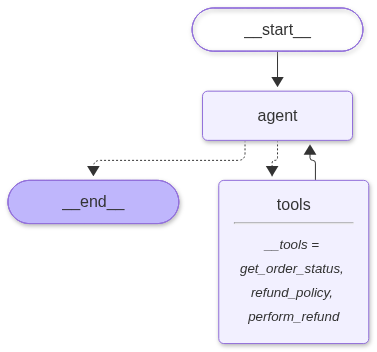

In [17]:
graph

In [18]:
# 6. Test the Agent with a multi-step query!
result = graph.invoke({
    "messages": [HumanMessage(content="Hi, I want to check the status of my two orders: ORD-101 and ORD-102. Also, I didn't like the item in ORD-101, so please process a refund for it and tell me the exact amount I will get back.")]
})

In [19]:
for msg in result["messages"]:
    print(f"[{type(msg).__name__}]: {msg.content} | Tool Calls: {getattr(msg, 'tool_calls', None)}")

[HumanMessage]: Hi, I want to check the status of my two orders: ORD-101 and ORD-102. Also, I didn't like the item in ORD-101, so please process a refund for it and tell me the exact amount I will get back. | Tool Calls: None
[AIMessage]: [] | Tool Calls: [{'name': 'get_order_status', 'args': {'order_id': 'ORD-101'}, 'id': 'call_15042147794851687649', 'type': 'tool_call'}, {'name': 'get_order_status', 'args': {'order_id': 'ORD-102'}, 'id': 'call_15042147794851687190', 'type': 'tool_call'}, {'name': 'refund_policy', 'args': {'order_id': 'ORD-101'}, 'id': 'call_15042147794851686731', 'type': 'tool_call'}]
[ToolMessage]: {"order_id": "ORD-101", "item_name": "Wireless Headphones", "price": 1500, "status": "Delivered", "days_since_delivery": 5} | Tool Calls: None
[ToolMessage]: {"order_id": "ORD-102", "item_name": "Mechanical Keyboard", "price": 2000, "status": "Shipped", "days_since_delivery": null} | Tool Calls: None
[ToolMessage]: Refund Accepted | Tool Calls: None
[AIMessage]: [] | Tool